<a href="https://colab.research.google.com/github/Tabatha651/METODOS_NUMERICOS/blob/main/diferenciasDivididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Diferencias Divididas

La fórmula de las **Diferencias Divididas de Newton** es un método utilizado para construir el polinomio de interpolación $P_n(x)$ que pasa exactamente por un conjunto de $n + 1$ de puntos conocidos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$.

A diferencia de la forma de Lagrange, los coeficientes del polinomio (las diferencias divididas) no dependen del punto $x$ de donde se quiere evaluar. Esto significa que, una vez construida la tabla, el mismo polinomio sirve para estimar cualquier valor intermedio sin necesidad de rehacer la tabla

Si se desea agregar un nuevo punto para mejorar la precisión (aumentar el grado del polinomio), basta con agregar una fila nueva al final de la tabla sin perder los cálculos anteriores.

### Forma general del polinomio
El polinomio interpolante de grado $n$ se expresa:

$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1} (x - x_j)$$


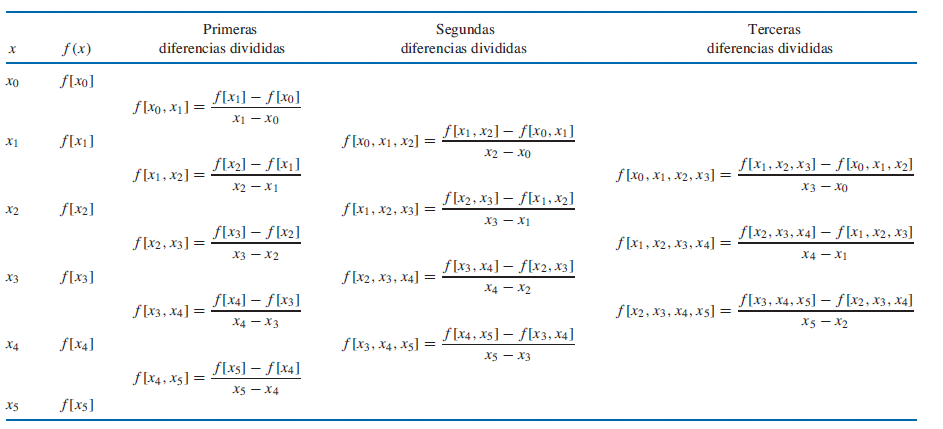

Para este código usaremos $5$ nodos ($n=4$) y buscamos aproximar el valor de $f(1.5)$:

1. **Columna 0 (Diferencias de orden cero):** Se colocan directamente los valores conocidos $F_{i,0} = f[x_i] = f(x_i)$.
2. **Cálculo iterativo de diferencias:** Cada columna siguiente ($j = 1, 2, \dots, n$) se calcula dividiendo la resta de dos diferencias consecutivas de la columna anterior entre la distancia de los nodos extremos correspondientes:

$$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$

Por ejemplo, para obtener la **primera diferencia dividida** entre los dos primeros nodos ($x_0 = 1.0$ y $x_1 = 1.3$), el algoritmo realiza la siguiente operación:

$$f[x_0, x_1] = \frac{f[x_1] - f[x_0]}{x_1 - x_0} = \frac{0.6200860 - 0.7651977}{1.3 - 1.0} = -0.4837057$$

3. **Evaluación del polinomio $P_4(1.5)$:** Finalmente, se toman los coeficientes $F_{0,0}, F_{1,1}, F_{2,2}, F_{3,3}, F_{4,4}$ y se sustituyen junto con $x = 1.5$ en la fórmula de Newton:

$$P_4(1.5)=0.7651977 + (-0.4837057)(1.5-1.0) + (-0.1087339)(1.5-1.0)(1.5-1.3) + (0.0658784)(1.5-1.0)(1.5-1.3)(1.5-1.6) + (0.0018251)(1.5-1.0)(1.5-1.3)(1.5- 1.6)(1.5-1.9)$$

Obteniendo así como resultado final **$P_4(1.5) \approx 0.5118200$**

In [18]:
#Diferencias Divididas 20/nov/2026
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

In [4]:
#-----------------------ENTRADA--------------------------------------------

x=1.5
nodos=[1.0, 1.3, 1.6, 1.9, 2.2]
f_x=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

n=len(nodos)-1        #4

In [5]:
#----------------ALGORITMO DIF DIVIDIDAS-------------------------------------

F = [[0.0 for _ in range(n + 1)] for _ in range(n + 1)]   #lista que contiene otras listas adentro F[fila][columna]     n+1=5       [0.0, 0.0, 0.0, 0.0, 0.0] repetimos 5 veces
for i in range(n + 1):                                    #Columna 0: Recorre todas las filas desde i=0 hasta i=4 toma cada valor de la lista f_x y lo guarda en la columna F[i][0]
  F[i][0]=f_x[i]

#Calculo de diferencias divididas
"Para fila:"
for i in range(1, n+1):                                     #Empezamos en 1 ya que que la fila 0 solo tiene un dato (F[0][0]), que ya llenamos en el paso anterior
  "Para columna:"
  for j in range(1, i + 1):
    F[i][j]=(F[i][j-1] - F[i-1][j-1]) / (nodos[i]-nodos[i-j])

In [10]:
#------------------IMPRESIÓN------------------------------------------------------

print(" x   |   f(x)    |  1ra dif   |  2da dif   |  3ra dif   |  4ta dif")
print("-"*70)

#Usaremos 2*n + 1 renglones visuales (renglones pares para nodos, impares para intermedios)
for fila in range(2*n + 1):
  #Columnas x y f(x): solo se imprimen en los renglones pares
  if fila%2==0:
    idx=fila//2
    print(f"{nodos[idx]:<4.1f} | {F[idx][0]:>9.7f} |", end="")
  else:
    print("     |           |", end="")

  #Columnas de diferencias divididas (j=1 hasta n)
  for j in range(1, n + 1):
    #Una diferencia de orden j aparece en el renglón: 2*i - j
    if (fila + j) % 2 == 0:
      i = (fila + j)//2
      if j<=i<=n:
        print(f" {F[i][j]:>10.7f} |", end="")
      else:
        print("            |", end="")
    else:
      print("            |", end="")

  print()  #Salto de línea al terminar cada renglón

print("-"*70)

 x   |   f(x)    |  1ra dif   |  2da dif   |  3ra dif   |  4ta dif
----------------------------------------------------------------------
1.0  | 0.7651977 |            |            |            |            |
     |           | -0.4837057 |            |            |            |
1.3  | 0.6200860 |            | -0.1087339 |            |            |
     |           | -0.5489460 |            |  0.0658784 |            |
1.6  | 0.4554022 |            | -0.0494433 |            |  0.0018251 |
     |           | -0.5786120 |            |  0.0680685 |            |
1.9  | 0.2818186 |            |  0.0118183 |            |            |
     |           | -0.5715210 |            |            |            |
2.2  | 0.1103623 |            |            |            |            |
----------------------------------------------------------------------


In [16]:
#------------------EVALUACIÓN DEL POLINOMIO-----------------------------------

#Empezamos con el primer término de la fórmula:F[0][0]
resultado_P=F[0][0]

#Esta variable irá guardando las multiplicaciones: (x-x0), luego (x-x0)*(x-x1), etc....
multiplicacion=1.0

#Recorremos desde i=1 hasta n (De 1 a 4)
for i in range(1, n+1):
  #Multiplicamos lo que ya llevábamos por el nuevo paréntesis (x-nodos[i-1])
  multiplicacion=multiplicacion * (x-nodos[i-1])

  #Sumamos el coeficiente de F[i][i] multiplicado por esos paréntesis
  resultado_P=resultado_P+(F[i][i]*multiplicacion)

#Imprimimos el resultado final redondeandolo a 7 decimales
print("El resultado aproximado P(1.5) es:", round(resultado_P, 7))

El resultado aproximado P(1.5) es: 0.51182


Coeficientes: [0.7651977, -0.4837056666666664, -0.10873388888888935, 0.06587839506172834, 0.0018251028806604353]
Polinomio P(x) = 0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


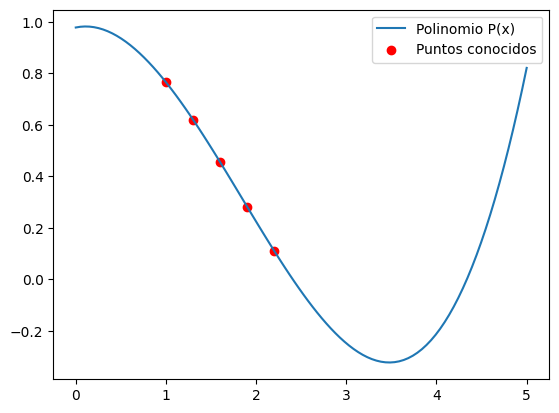

In [20]:
#------------------COEFICIENTES POLINOMIO Y GRÁFICA--------------------------
import matplotlib.pyplot as plt  #Libreria para dibujar gráficas
import numpy as np  #Para crear listas
import sympy as sp  #Para escribir ecuaciones matemáticas con letras

#Guardamos los coeficientes (F[i][i]) en una lista normal
coeficientes = []
for i in range(n+1):
  coeficientes.append(F[i][i])

print("Coeficientes:", coeficientes)


#Funcion que arma el polinomio con SymPy y lo grafica
def graficar_newton(coefs, nodos, f_x):
  X=sp.Symbol("x")  #Creamos la letra 'x' como variable matemática
  P=coefs[0]  #Empezamos el polinomio con el primer coeficiente (F00)
  parentesis=1  #Aquí iremos acumulando (x-x0), (x-x0)(x-x1), etc.....

  #Recorremos los demas coeficientes para armar el polinomio
  for i in range(1, len(coefs)):
    parentesis = parentesis * (X-nodos[i-1])  #Agregamos el siguiente (x-xi)
    P=P+coefs[i] * parentesis  #Sumamos el nuevo término al polinomio

  P_limpio=sp.expand(P)  #Desarrollamos las multiplicaciones para ver el polinomio ordenado
  print("Polinomio P(x) =", P_limpio)  #Mostramos la ecuación final en pantalla

  funcion_P=sp.lambdify(X, P_limpio, "numpy")
  x_linea=np.linspace(0, 5, 100)

  plt.plot(x_linea, funcion_P(x_linea), label="Polinomio P(x)")  #Dibuja la curva
  plt.scatter(nodos, f_x, color="red", label="Puntos conocidos")  #Dibuja los 5 nodos
  plt.legend()
  plt.show()

graficar_newton(coeficientes, nodos, f_x)